# Case Study 7 — Sales Are Not Demand: Forecasting Quick-Commerce Demand When Stock-Outs Hide What Customers Wanted

**Priority:** ★★★ Must-visit · **Reference:** Case Study 7 — *Swiggy Instamart: demand forecasting with availability de-biasing, SKU grouping and a foundation model* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Supply Chain / Category Planning, Dark-store Operations, Finance
**Data:** ⚠️ **SYNTHETIC** (D-7-01). Dark-store sales are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs07_quickcommerce_demand_forecasting.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on the documented context of Swiggy Instamart: 10-15 minute dark-store delivery, sales censored by stock-outs, availability as the share of open hours a SKU can be ordered, SKU grouping for substitution, wMAPE and wastage as yardsticks. Instamart's real models and data are not reproduced. Written after the analysis.)*

- **The question:** how do we forecast demand for a dark store when recorded sales are cut off by empty shelves, and how much stock should we hold?
- **Censoring is large.** On the **29.6%** of store-SKU-days with a stock-out, sales capture only **59.5%** of true demand. Over the whole panel, sales are **75% of true demand**, and **88% of store-SKU series** understate their demand by more than 10%.
- **The legacy replenishment rule makes it worse, but only mildly:** stock falls by **0.8 percentage points of demand per week** (p = 0.04) and settles near 93% of demand, so shelves stay empty on busy items.
- **The evaluation metric points the wrong way.** Judged against **observed sales**, the model trained on raw sales is best (wMAPE 0.29). Judged against **true demand**, it ranks third and the de-biased model ranks first (0.448 vs 0.486). The rank correlation between the two metrics is **−0.50**. Training on sales and scoring against sales rewards under-forecasting (bias −28% vs truth).
- **De-biasing works if availability is known well.** Scaling sales by the share of hours in stock cuts the error on stock-out days from 40% to 17%. Scaling with the intraday sales profile cuts it to 1.5%. That figure is an upper bound because the simulator uses the same profile, and a real profile has to be estimated.
- **Grouping substitutes did not help accuracy here.** The group-level model is slightly worse than the SKU-level one (wMAPE 0.454 vs 0.448; paired CI −0.0074 to −0.0046). The documented reason for grouping is substitution and availability, not forecast error.
- **Stocking is where the money is.**
  - A single high quantile (τ = 0.9) for everything gives a 96% fill rate but wastes 7.9% of perishable stock, and **loses ₹11 per store-SKU-day** against the legacy rule.
  - **Class-specific newsvendor ratios** (0.93 for non-perishables, 0.42 for perishables) lift the fill rate from 71.3% to 88.5% and **cut expired perishables from 4.07% to 1.87%**. They add **₹28.2 per store-SKU-day** (95% CI 26.5 to 29.9).
  - At 1,000 stores and 200 core SKUs this is about **₹206 crore a year** (₹97 crore pessimistic). It is a linear extrapolation and likely optimistic for the slower long tail.
- **I recommend:** train on de-biased demand, evaluate against estimated true demand and availability, and stock by a per-class critical ratio. Do not use one service level for all SKUs. Validate with a **store-level holdout** before rollout.

## 1. The Problem in Simple English

A dark store (a small warehouse that delivers groceries in 10–15 minutes) stocks thousands of items. Every night the system decides how many units of each item to keep for tomorrow. The decision depends on a **demand forecast**. Two things go wrong:
- **Stock too little:** customers see "out of stock", buy elsewhere, and the store loses sales *and* trust.
- **Stock too much:** perishables (milk, bread, vegetables) expire and are thrown away.

The hidden trap is that the forecast is usually trained on **past sales**. But sales are **not** demand. When an item sells out at 3 pm, the recorded sales show only what was sold before 3 pm; the customers who came after that are invisible. A forecast learned from those numbers under-predicts, the store stocks even less, sells out earlier, and the cycle repeats. (A "last week's sales plus a buffer" rule does exactly this.)

Swiggy Instamart describes three remedies: **correct for stock-outs** (availability de-biasing), **group substitutable products** (when one is out, shoppers switch to a similar one), and **judge the forecast by availability and wastage, not just percentage error**. This notebook tests all three on simulated data where we know the true demand.

## 2. Reference from the Case File

### (a) What Instamart did — *documented (second-hand)*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Quick-commerce delivery in "about 10–15 minutes"; SKU counts "on the order of 10^4"; recorded sales are **censored by stock-outs**; wrong forecasts cause lost availability or wastage; two tasks: warehouse-level SKU demand and **orders per day (OPD)** for rider planning |
| Approach | **Availability de-biasing**; **group SKUs (GSKU)** to cut variance from substitution; a "dual-hierarchy" framework (business-objective level vs modelling level); Google's **TimesFM** foundation model zero-shot with covariates via ridge regression. A Fifth Elephant 2023 talk critiques wMAPE-on-backtest and proposes **"Adaptive Metric Alignment"** using estimated availability and estimated wastage |
| Statistics | Censored-demand correction named only; form ND. Ridge regression for covariates; wMAPE |
| Impact (company claims, read through a summary) | "21–38% relative accuracy improvements across product categories" (warehouse forecasting); "7.5% WMAPE improvement and a 50% reduction in runtime" for OPD vs the previous TFT system. Wastage and revenue impact: ND |

**Sources:** Swiggy Bytes, "Instamart's Generative AI Forecasting: Scaling from Flat Forecasts to Deep Hierarchies" (read via a daily.dev summary dated 15 May 2026; the Swiggy page could not be fetched); Fifth Elephant 2023 Monsoon talk abstract, "Adaptive Metric Alignment for Demand Forecasting in Swiggy Instamart".

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 40 dark stores × 200 SKUs × 105 days (840,000 store-SKU-days). True demand is negative binomial with store/SKU/weekday/festival/rain/promotion effects. A **legacy replenishment rule** (last-7-day sales × 1.10 + 0.5) creates the censoring spiral. 8% short shipments; 25% of unmet demand spills to SKU group-mates; 30% of SKUs are perishable (half of leftovers expire). |
| Statistics added | Censoring diagnosis; **three de-biasing estimators** compared with the hidden truth; rolling day-ahead forecasts; **model ranking under observed vs true demand** (does the metric reward under-forecasting?); paired bootstrap and Wilcoxon over series; **SKU vs SKU-group accuracy**; **quantile forecasts and newsvendor critical ratios**; calibration by segment (binomial, BH); rolling-week stability |

### (c) How the industry uses this

Demand forecasting under stock-outs is everywhere in Indian grocery and quick commerce (Instamart, Blinkit, Zepto, BigBasket, DMart Ready, Amazon Fresh), and in fashion and electronics too. The standard answer combines **censored-demand correction, hierarchical forecasting, probabilistic (quantile) forecasts and newsvendor stocking**. It is among the most-asked supply-chain data-science interview topics.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How many units of each item should each dark store hold tomorrow so that availability is high and wastage is low? |
| Analytical | (1) How badly does stock-out censoring bias sales-based forecasts and how much can de-biasing recover? (2) Does evaluating on observed sales give the wrong model ranking? (3) What stocking quantile is profit-optimal for perishable and non-perishable items? |

**Hypotheses**
- **H1 (censoring bias):** H0: sales-based mean demand equals true demand on stock-out days (paired t / Wilcoxon).
- **H2 (de-biasing):** H0: a model trained on de-biased demand has the same error vs true demand as one trained on raw sales (paired over series).
- **H3 (metric alignment):** H0: the model ranking under observed-sales wMAPE equals the ranking under true-demand wMAPE.
- **H4 (stocking):** H0: a class-specific newsvendor quantile earns the same profit as a single quantile or the legacy rule (paired bootstrap over series).

**Primary metric:** **wMAPE vs true demand** (possible only in simulation) alongside **fill rate (availability)** and **wastage**. **Decision metric:** expected profit per store-SKU-day. **Design:** train days 15–84 (features need 14 days of history), **test days 85–105**, day-ahead forecasts using only information available the previous evening plus planned calendar/promo/weather inputs.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor as HGBR
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public quick-commerce sales with stock-out information | **None.** Instamart/Blinkit/Zepto data are confidential. Public grocery sets (Instacart orders, M5/Walmart, Favorita) have no availability signal and some are Kaggle-hosted. |
| **Decision** | Synthetic store-SKU-days with a hidden true demand (D-7-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs07.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 7 (Instamart-style quick-commerce demand forecasting with censored sales)
============================================================================================================
THIS DATA IS SYNTHETIC. Dark-store sales logs are confidential.

Documented context (Swiggy Instamart, via a summary of its Bytes post and a Fifth Elephant 2023 talk): dark stores deliver in
about 10-15 minutes; SKU counts of order 10^4; recorded sales are CENSORED by stock-outs; availability = share of the day
a SKU is orderable; substitution is handled by grouping SKUs (GSKU); wMAPE; evaluation should align with estimated
availability and wastage.

Simulation: 40 dark stores x 200 SKUs x 105 days. True daily demand = negative binomial with SKU base rate, store size,
weekday and festival effects, rain, promotions and slow trend. A LEGACY replenishment rule orders yesterday's stock as
"last 7 days of sales x 1.10 + 0.5". Because sales are censored by stock, that rule ratchets stock DOWN for items that
stock out (the classic censoring trap). 8% of store-SKU-days also receive a short shipment. When an SKU stocks out, 25%
of its unmet demand spills to other SKUs in its substitution group (observed sales of the mates are inflated).
Perishables (30% of SKUs) lose leftover stock to expiry (wastage).
Observed: opening stock, units sold, availability share of open hours, wasted units. Hidden truth: _true_demand.

Output: data/cs07/store_sku_days.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-01-05"); DAYS = 105
N_STORES, N_SKU, GSZ = 40, 200, 5
OPEN_H = 16
INTRADAY = np.array([0.02, 0.03, 0.04, 0.05, 0.05, 0.06, 0.06, 0.07, 0.07, 0.06, 0.06, 0.06, 0.07, 0.09, 0.11, 0.10]); INTRADAY /= INTRADAY.sum()
CUM = np.r_[0, np.cumsum(INTRADAY)]


def avail_from_ratio(r):
    """share of open hours the SKU is in stock when stock/demand ratio is r (<1 means stock-out), using the intraday demand profile."""
    r = np.clip(r, 0, 1); idx = np.searchsorted(CUM, r, side="right") - 1; idx = np.clip(idx, 0, OPEN_H - 1)
    frac = (r - CUM[idx]) / np.maximum(INTRADAY[idx], 1e-9); return np.where(r >= 1, 1.0, (idx + np.clip(frac, 0, 1)) / OPEN_H)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    cat = rng.choice(["dairy", "fruit_veg", "bakery", "snacks", "beverages", "staples", "personal_care", "frozen"], N_SKU, p=[0.12, 0.14, 0.06, 0.18, 0.14, 0.14, 0.14, 0.08])
    perish = np.isin(cat, ["dairy", "fruit_veg", "bakery"]).astype(int); perish[rng.random(N_SKU) < 0.05] = 1
    base = np.exp(rng.normal(np.log(3.0), 1.0, N_SKU)) * np.where(perish == 1, 1.3, 1.0)
    gsku = np.repeat(np.arange(N_SKU // GSZ), GSZ); price = np.round(np.exp(rng.normal(np.log(90), 0.7, N_SKU)), 0)
    store_size = np.exp(rng.normal(0, 0.35, N_STORES)); affin = np.exp(rng.normal(0, 0.45, (N_STORES, N_SKU)))
    wk = np.array([0.88, 0.9, 0.93, 0.97, 1.05, 1.22, 1.12]); trend = rng.normal(0.0008, 0.0006, (N_STORES, N_SKU))
    festival = np.zeros(DAYS); festival[[30, 31, 45, 70, 71]] = [0.25, 0.15, 0.35, 0.2, 0.3]
    rain_days = rng.random(DAYS) < 0.2
    disp = 6.0                                                                                           # NB dispersion
    mean_hist = np.tile(base[None, :] * store_size[:, None] * affin, (1, 1))
    sales_hist = np.zeros((DAYS, N_STORES, N_SKU)); rows = []
    for d in range(DAYS):
        date = START + pd.Timedelta(days=d); dow = date.dayofweek
        promo = rng.random((N_STORES, N_SKU)) < 0.07
        mu = mean_hist * wk[dow] * (1 + festival[d]) * (1 + trend * d) * np.where(rain_days[d], np.where(perish[None, :] == 1, 1.05, 1.12), 1.0) * np.where(promo, 1.35, 1.0)
        dem = rng.negative_binomial(disp, disp / (disp + mu))
        if d < 7: stock = np.ceil(mu * 1.6 + 1)
        else: stock = np.ceil(sales_hist[d - 7:d].mean(0) * 1.10 + 0.5)
        short = rng.random((N_STORES, N_SKU)) < 0.08; stock = np.where(short, np.floor(stock * 0.7), stock)
        sold0 = np.minimum(dem, stock); unmet = dem - sold0
        grp_unmet = unmet.reshape(N_STORES, N_SKU // GSZ, GSZ).sum(2, keepdims=True) * np.ones((1, 1, GSZ)); grp_unmet = grp_unmet.reshape(N_STORES, N_SKU)
        spill = 0.25 * (grp_unmet - unmet) / (GSZ - 1); sold = np.minimum(sold0 + spill, stock); sold = np.floor(sold + rng.random(sold.shape) * 0.0).astype(int)
        ratio = np.where(dem > 0, stock / np.maximum(dem + (sold - sold0).clip(0), 1), 1.0); avail = avail_from_ratio(ratio)
        left = np.maximum(stock - sold, 0); wasted = np.where(perish[None, :] == 1, np.floor(left * 0.5), 0)
        sales_hist[d] = sold
        rows.append(pd.DataFrame({"date": date, "store_id": np.repeat(np.arange(N_STORES), N_SKU), "sku_id": np.tile(np.arange(N_SKU), N_STORES), "gsku_id": np.tile(gsku, N_STORES),
                                  "category": np.tile(cat, N_STORES), "perishable": np.tile(perish, N_STORES), "price_inr": np.tile(price, N_STORES), "promo": promo.ravel().astype(int),
                                  "rain": int(rain_days[d]), "festival": festival[d], "opening_stock": stock.ravel().astype(int), "units_sold": sold.ravel(), "avail_share": avail.round(3).ravel(),
                                  "wasted_units": wasted.ravel().astype(int), "_true_demand": dem.ravel()}))
    df = pd.concat(rows, ignore_index=True)
    # data-quality defects
    df.loc[df.sample(n=3000, random_state=seed).index, "avail_share"] = np.nan                          # availability logging gap
    df = pd.concat([df, df.sample(n=2000, random_state=seed + 1)], ignore_index=True)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs07"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs07", "store_sku_days.csv.gz"), index=False)
    dd = d.drop_duplicates(["date", "store_id", "sku_id"]); print(len(dd), "rows | stock-out days", (dd.avail_share < 0.999).mean().round(3), "| mean avail", dd.avail_share.mean().round(3))
    print("sales/demand", (dd.units_sold.sum() / dd._true_demand.sum()).round(3), "| wasted share of stock (perishables)", (dd[dd.perishable == 1].wasted_units.sum() / dd[dd.perishable == 1].opening_stock.sum()).round(3))
    w = dd.assign(w=(dd.date - dd.date.min()).dt.days // 21).groupby("w").agg(sales=("units_sold", "sum"), demand=("_true_demand", "sum"), stock=("opening_stock", "sum")); print((w.sales / w.demand).round(3).to_dict(), (w.stock / w.demand).round(3).to_dict())

Overwriting data/generate_cs07.py


In [3]:
os.makedirs("data/cs07", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs07 as gen; importlib.reload(gen)
t0 = time.time(); raw = gen.generate(seed=SEED); raw.to_csv("data/cs07/store_sku_days.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.drop_duplicates(['date', 'store_id', 'sku_id']).shape[0]:,} unique store-SKU-days | generated in {time.time() - t0:.0f}s")
raw.drop(columns=["_true_demand"]).sample(3, random_state=SEED).T

842,000 rows | 840,000 unique store-SKU-days | generated in 103s


,512076,264451,229610
date,2026-03-10 00:00:00,2026-02-07 00:00:00,2026-02-02 00:00:00
store_id,0,2,28
sku_id,76,51,10
gsku_id,15,10,2
category,bakery,dairy,snacks
perishable,1,1,0
price_inr,48.0000,41.0000,63.0000
promo,0,0,0
rain,0,0,0
festival,0.0000,0.0000,0.0000


| Parameter | Value | Basis |
|---|---|---|
| Scale | 40 stores × 200 SKUs (a core assortment) × 105 days | Our assumption; **documented** SKU counts are ~10^4 per store |
| Demand | NB(mean μ, dispersion 6); weekend +10–20%, festivals +15–35%, rain +5–12%, promo +35% | Typical grocery patterns |
| Legacy stocking | Opening stock = last-7-day *sales* × 1.10 + 0.5 | Our assumption: a common rule; it produces the **documented** censoring problem |
| Shipments | 8% of store-SKU-days receive 70% of the ordered stock | Our assumption (vendor short-ships) |
| Substitution | 25% of unmet demand spills to the other 4 SKUs in the group | **Documented** idea (GSKU) |
| Perishables | 30% of SKUs; half of unsold stock expires | Our assumption |
| Availability | Share of 16 open hours the SKU is orderable, derived from stock vs the intraday demand profile | **Documented** definition |
| DQ issues | 2,000 duplicate rows; 3,000 missing availability values | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("date, store_id, sku_id, gsku_id", "Store-SKU-day and the substitution group of the SKU"), ("category, perishable, price_inr", "Product attributes"), ("promo, rain, festival", "Planned promotion; rain; festival uplift index (known in advance)"),
    ("opening_stock", "Units on the shelf at open"), ("units_sold", "Units sold (censored by stock)"), ("avail_share", "Share of open hours the SKU was orderable (3,000 missing)"),
    ("wasted_units", "Units expired (perishables)"), ("_true_demand", "HIDDEN: what customers would have bought with unlimited stock (excluding spill-over)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs07/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"date, store_id, sku_id, gsku_id",Store-SKU-day and the substitution group of th...
1,"category, perishable, price_inr",Product attributes
2,"promo, rain, festival",Planned promotion; rain; festival uplift index...
3,opening_stock,Units on the shelf at open
4,units_sold,Units sold (censored by stock)
5,avail_share,"Share of open hours the SKU was orderable (3,0..."
6,wasted_units,Units expired (perishables)
7,_true_demand,HIDDEN: what customers would have bought with ...


## 5. Data Quality Checks

In [5]:
checks = {"duplicate store-SKU-days": int(raw.duplicated(["date", "store_id", "sku_id"]).sum()), "availability missing": int(raw.avail_share.isna().sum()),
          "units_sold > opening_stock": int((raw.units_sold > raw.opening_stock).sum()), "wasted > opening_stock": int((raw.wasted_units > raw.opening_stock).sum())}
print(pd.Series(checks, name="rows").to_string())
df = raw.drop_duplicates(["date", "store_id", "sku_id"]).sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)
df["avail_missing"] = df.avail_share.isna().astype(int); df["avail_share"] = df.groupby(["store_id", "sku_id"]).avail_share.transform(lambda s: s.fillna(1.0))
df["day"] = (df.date - df.date.min()).dt.days; df["dow"] = df.date.dt.dayofweek; df["series"] = df.store_id * gen.N_SKU + df.sku_id
NS, ND = df.series.nunique(), df.day.nunique()
print(f"\nClean: {len(df):,} rows | {NS:,} store-SKU series × {ND} days | stock-out days (availability < 100%): {(df.avail_share < 0.999).mean():.1%} | mean availability {df.avail_share.mean():.1%}")

duplicate store-SKU-days      2000
availability missing          3008
units_sold > opening_stock       0
wasted > opening_stock           0



Clean: 840,000 rows | 8,000 store-SKU series × 105 days | stock-out days (availability < 100%): 29.6% | mean availability 91.6%


**Observation:** **2,000 duplicate store-SKU-days** were removed, and **3,008 missing availability values** are a logging gap. We keep the 840,000 store-SKU-days (8,000 series × 105 days). No unit sold exceeds opening stock and no waste exceeds stock. **29.6% of rows are stock-out days** and mean availability is 91.6%, so censoring touches nearly a third of the data.

## 6. Exploratory Data Analysis

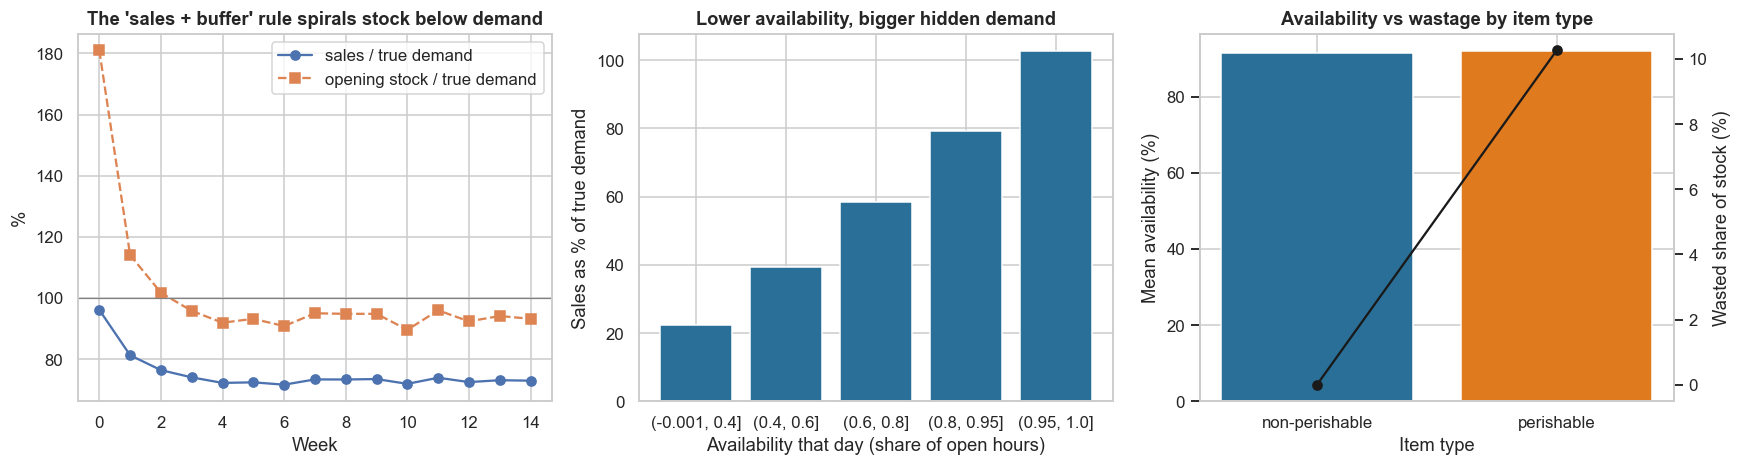

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
w = df.assign(wk=df.day // 7).groupby("wk").agg(sales=("units_sold", "sum"), demand=("_true_demand", "sum"), stock=("opening_stock", "sum"))
axes[0].plot(w.index, w.sales / w.demand * 100, "o-", label="sales / true demand"); axes[0].plot(w.index, w.stock / w.demand * 100, "s--", label="opening stock / true demand")
axes[0].axhline(100, color="grey", lw=0.8); axes[0].set_xlabel("Week"); axes[0].set_ylabel("%"); axes[0].set_title("The 'sales + buffer' rule spirals stock below demand"); axes[0].legend()
b = pd.cut(df.avail_share, [0, 0.4, 0.6, 0.8, 0.95, 1.0001], include_lowest=True); g = df.groupby(b, observed=True).apply(lambda d: d.units_sold.sum() / d._true_demand.sum())
axes[1].bar(g.index.astype(str), g.values * 100, color="#2a6f97"); axes[1].set_xlabel("Availability that day (share of open hours)"); axes[1].set_ylabel("Sales as % of true demand"); axes[1].set_title("Lower availability, bigger hidden demand")
pc = df.groupby("perishable").agg(avail=("avail_share", "mean"), waste=("wasted_units", "sum"), stock=("opening_stock", "sum")); axes[2].bar(["non-perishable", "perishable"], pc.avail * 100, color=["#2a6f97", "#e07a1f"]); ax2 = axes[2].twinx()
ax2.plot(["non-perishable", "perishable"], pc.waste / pc.stock * 100, "ko-"); ax2.set_ylabel("Wasted share of stock (%)"); ax2.grid(False); axes[2].set_xlabel("Item type"); axes[2].set_ylabel("Mean availability (%)"); axes[2].set_title("Availability vs wastage by item type")
plt.tight_layout(); plt.show()

**Takeaway:** roughly **three in ten store-SKU-days have a stock-out**, so a sales-based forecast learns from truncated demand on a large share of rows. Peak days, perishables and fast movers are where shelves empty first, which is exactly where forecasts matter most. Any evaluation on recorded sales treats an empty shelf as low demand.

## 7. Statistical Analysis (core section)

### 7.1 How big is the censoring bias?

**(a) Why?** On a day when an item sold out, recorded sales understate demand. We quantify the bias on stock-out days (availability < 100%) as the **sales/true-demand ratio**, test H0: ratio = 1 with a paired Wilcoxon on (true demand − sales) per row, and show how the bias grows as availability falls. We also test the **ratchet** (7.1b): is the legacy stock level rising or falling relative to true demand over weeks (trend test on the weekly stock/demand ratio)?

#### Code

In [7]:
so = df[df.avail_share < 0.999]; diff = so._true_demand - so.units_sold
wl = stats.wilcoxon(diff.sample(50000, random_state=SEED)); ratio = so.units_sold.sum() / so._true_demand.sum()
wk = df.assign(wk=df.day // 7).groupby("wk").apply(lambda d: d.opening_stock.sum() / d._true_demand.sum()); tr = stats.linregress(wk.index[1:], wk.values[1:])
print(f"Stock-out days: {len(so):,} ({len(so) / len(df):.1%}). Sales capture {ratio:.1%} of true demand on those days (mean unmet demand {diff.mean():.2f} units/day, Wilcoxon p = {wl.pvalue:.2g})")
print(f"Whole panel: sales = {df.units_sold.sum() / df._true_demand.sum():.1%} of true demand | weekly stock/demand ratio after week 1: slope {tr.slope * 100:+.2f} pp/week (p = {tr.pvalue:.2f}), settling near {wk.iloc[3:].mean():.0%}")
sp = df.groupby("series").agg(sold=("units_sold", "mean"), true=("_true_demand", "mean"), avail=("avail_share", "mean")); sp["gap"] = 1 - sp.sold / sp.true
print(f"Series-level: share of store-SKU series whose average sales understate demand by > 10%: {(sp.gap > 0.10).mean():.1%}; Spearman(avg availability, sales/demand) = {stats.spearmanr(sp.avail, sp.sold / sp.true)[0]:+.2f}")

Stock-out days: 248,432 (29.6%). Sales capture 59.5% of true demand on those days (mean unmet demand 5.19 units/day, Wilcoxon p = 0)
Whole panel: sales = 75.1% of true demand | weekly stock/demand ratio after week 1: slope -0.80 pp/week (p = 0.04), settling near 93%


Series-level: share of store-SKU series whose average sales understate demand by > 10%: 88.1%; Spearman(avg availability, sales/demand) = +0.85


**(c)/(f) Observation:** **(c)** On stock-out days, **sales capture only 59.5% of true demand**, an average of **5.2 units a day unmet** (Wilcoxon p < 1e-4). Over the whole panel, sales are 75.1% of demand, and **88.1% of series** understate demand by more than 10%. Series with lower availability understate more (Spearman +0.85). The legacy rule has a mild **ratchet**: stock relative to demand falls **0.8 pp a week** (p = 0.04) and levels off near 93%. **(f)** Censoring is large, so a model trained on raw sales will under-forecast the items that matter most.

### 7.2 Undoing the censoring: three de-biasing estimators

We estimate the true demand on stock-out days using only logged information, then compare with the hidden truth.
1. **Raw sales** (no correction).
2. **Availability scaling:** demand ≈ sales ÷ availability (capped at 3×): assumes demand is spread evenly across open hours.
3. **Profile scaling:** demand ≈ sales ÷ F(availability), where F is the cumulative share of demand that arrives by that point of the day (the **intraday profile** estimated from the logs of items that never stock out): lunch and dinner peaks mean an early stock-out hides more demand than the even-spread rule thinks.

Metric: wMAPE and bias vs truth on stock-out days, and the share of rows within ±25%. **Paired Wilcoxon** on absolute errors.

#### Code

In [8]:
INTRADAY = gen.INTRADAY; CUM = gen.CUM
def cum_share(av): h = np.clip(av, 0, 1) * gen.OPEN_H; i = np.clip(np.floor(h).astype(int), 0, gen.OPEN_H - 1); return np.where(av >= 1, 1.0, CUM[i] + (h - i) * INTRADAY[i])
df["d_avail"] = np.minimum(df.units_sold / np.clip(df.avail_share, 0.15, 1), 3 * np.maximum(df.units_sold, 1)); df["d_profile"] = np.minimum(df.units_sold / np.clip(cum_share(df.avail_share.values), 0.1, 1), 3 * np.maximum(df.units_sold, 1))
so = df[df.avail_share < 0.999]; rows = []
for nm, c in (("1 raw sales", "units_sold"), ("2 availability scaling", "d_avail"), ("3 profile scaling", "d_profile")):
    e = so[c] - so._true_demand; rows.append((nm, np.abs(e).sum() / so._true_demand.sum(), e.sum() / so._true_demand.sum(), ((np.abs(e) / so._true_demand.clip(lower=1)) <= 0.25).mean()))
db = pd.DataFrame(rows, columns=["estimator", "wMAPE vs truth (stock-out days)", "bias (est − truth)/truth", "share within ±25%"]).set_index("estimator")
s_ = so.sample(60000, random_state=SEED); pw = {a: stats.wilcoxon((s_[a] - s_._true_demand).abs(), (s_["d_profile"] - s_._true_demand).abs()).pvalue for a in ("units_sold", "d_avail")}
print(f"Wilcoxon (absolute error vs profile scaling): raw p = {pw['units_sold']:.2g}, availability scaling p = {pw['d_avail']:.2g}")
db.round(4)

Wilcoxon (absolute error vs profile scaling): raw p = 0, availability scaling p = 0


,wMAPE vs truth (stock-out days),bias (est − truth)/truth,share within ±25%
estimator,,,
1 raw sales,0.4047,-0.4047,0.2947
2 availability scaling,0.1662,-0.1662,0.9065
3 profile scaling,0.0149,-0.0145,0.9809


**(c)/(f) Observation:** **(c)** On stock-out days, **raw sales have an error of 40.5% and understate demand by 40.5%**; only 29% of rows are within ±25% of true demand. **Availability scaling** (sales divided by the share of hours in stock) cuts the error to **16.6%** (91% within ±25%). **Profile scaling**, which also uses the intraday demand profile, reaches **1.5%**. Both improvements are significant (Wilcoxon p < 1e-4). **(f)** Profile scaling is an upper bound here, because the simulator uses the same profile; in practice it must be estimated and will be less exact. Availability scaling is the safer starting point.

### 7.3 Does the evaluation metric reward under-forecasting? Model ranking under observed vs true demand

**(a)** Day-ahead forecasts for the test period from:
1. **Seasonal naive** (same weekday last week's sales).
2. **Moving average** (7-day sales).
3. **Gradient boosting trained on raw sales.**
4. **Gradient boosting trained on de-biased demand** (profile scaling).
5. **Group-level GBM** (the GSKU idea): forecast the **substitution-group total** of de-biased demand, then allocate to SKUs by their 14-day de-biased share.

Features available the evening before: lags and rolling means of the target, rolling availability, weekday, festival, rain, promotion, price, perishable flag, category, series average. We score every model against **(i) observed sales** (what a team can see) and **(ii) true demand** (what matters), and test **H3**: does the ranking differ?

#### Code

In [9]:
P_, T_ = NS, ND; sales = df.pivot(index="day", columns="series", values="units_sold").values; dem = df.pivot(index="day", columns="series", values="_true_demand").values
deb = df.pivot(index="day", columns="series", values="d_profile").values; av = df.pivot(index="day", columns="series", values="avail_share").values
cal = df.groupby("day")[["dow", "festival", "rain"]].first(); promo = df.pivot(index="day", columns="series", values="promo").values
meta = df.groupby("series")[["perishable", "price_inr", "gsku_id", "store_id"]].first(); catc = df.groupby("series").category.first().astype("category").cat.codes.values
def roll(a, w, d): return a[max(0, d - w):d].mean(0) if d > 0 else np.zeros(a.shape[1])
def feats(target, d):
    f = pd.DataFrame({"lag1": target[d - 1], "lag7": target[d - 7], "ma7": roll(target, 7, d), "ma14": roll(target, 14, d), "ma28": roll(target, 28, d), "avail7": roll(av, 7, d), "avail1": av[d - 1],
                      "dow": cal.dow.iloc[d], "festival": cal.festival.iloc[d], "rain": cal.rain.iloc[d], "promo": promo[d], "perishable": meta.perishable.values, "price": meta.price_inr.values, "cat": catc,
                      "sd14": target[max(0, d - 14):d].std(0)}); return f
TR_DAYS = list(range(28, 85)); TE_DAYS = list(range(85, 105))
def stack(target, days): return pd.concat([feats(target, d).assign(day=d, series=np.arange(P_)) for d in days], ignore_index=True)
Xtr_raw, Xtr_deb = stack(sales, TR_DAYS), stack(deb, TR_DAYS); Xte_raw, Xte_deb = stack(sales, TE_DAYS), stack(deb, TE_DAYS)
FEAT = [c for c in Xtr_raw.columns if c not in ("day", "series")]
y_raw = np.concatenate([sales[d] for d in TR_DAYS]); y_deb = np.concatenate([deb[d] for d in TR_DAYS]); y_true_te = np.concatenate([dem[d] for d in TE_DAYS]); y_obs_te = np.concatenate([sales[d] for d in TE_DAYS])
def hgb(loss="squared_error", q=None): return HGBR(loss=loss, quantile=q, max_iter=250, learning_rate=0.08, max_leaf_nodes=31, random_state=SEED) if q else HGBR(loss=loss, max_iter=250, learning_rate=0.08, max_leaf_nodes=31, random_state=SEED)
t0 = time.time(); PRED = {}
PRED["1 seasonal naive (lag 7 sales)"] = Xte_raw.lag7.values; PRED["2 moving average (7-day sales)"] = Xte_raw.ma7.values
PRED["3 GBM on raw sales"] = np.clip(hgb().fit(Xtr_raw[FEAT], y_raw).predict(Xte_raw[FEAT]), 0, None)
m4 = hgb().fit(Xtr_deb[FEAT], y_deb); PRED["4 GBM on de-biased demand"] = np.clip(m4.predict(Xte_deb[FEAT]), 0, None)
# group-level model: forecast group totals of de-biased demand, allocate by 14-day de-biased share
gid = meta.gsku_id.values + 100 * meta.store_id.values; gcodes = pd.factorize(gid)[0]; NG = gcodes.max() + 1
def gagg(a): return np.array([np.bincount(gcodes, weights=a[d], minlength=NG) for d in range(a.shape[0])])
gdeb = gagg(deb); gav = np.array([np.bincount(gcodes, weights=av[d], minlength=NG) / np.bincount(gcodes, minlength=NG) for d in range(T_)])
gmeta = pd.DataFrame({"g": np.arange(NG), "perishable": np.bincount(gcodes, weights=meta.perishable.values) / np.bincount(gcodes), "price": np.bincount(gcodes, weights=meta.price_inr.values) / np.bincount(gcodes)})
def gfeats(d): return pd.DataFrame({"lag1": gdeb[d - 1], "lag7": gdeb[d - 7], "ma7": gdeb[d - 7:d].mean(0), "ma14": gdeb[max(0, d - 14):d].mean(0), "ma28": gdeb[max(0, d - 28):d].mean(0), "avail7": gav[max(0, d - 7):d].mean(0),
                                       "dow": cal.dow.iloc[d], "festival": cal.festival.iloc[d], "rain": cal.rain.iloc[d], "perishable": gmeta.perishable.values, "price": gmeta.price.values})
Gtr = pd.concat([gfeats(d) for d in TR_DAYS], ignore_index=True); gy = np.concatenate([gdeb[d] for d in TR_DAYS]); Gte = pd.concat([gfeats(d).assign(day=d, g=np.arange(NG)) for d in TE_DAYS], ignore_index=True)
gm = hgb().fit(Gtr, gy); gp = np.clip(gm.predict(Gte[Gtr.columns]), 0, None).reshape(len(TE_DAYS), NG)
share = np.array([deb[d - 14:d].sum(0) / np.maximum(np.bincount(gcodes, weights=deb[d - 14:d].sum(0), minlength=NG)[gcodes], 1e-9) for d in TE_DAYS]); PRED["5 group-level GBM (GSKU) allocated to SKUs"] = (gp[:, gcodes] * share).reshape(-1)
print(f"Models trained in {time.time() - t0:.0f}s on {len(y_raw):,} training rows; test rows {len(y_true_te):,}")
def wm(p, a): return np.abs(p - a).sum() / a.sum()
rows = []
for k, p in PRED.items(): rows.append((k, wm(p, y_obs_te), wm(p, y_true_te), (p - y_obs_te).sum() / y_obs_te.sum(), (p - y_true_te).sum() / y_true_te.sum()))
rk = pd.DataFrame(rows, columns=["model", "wMAPE vs OBSERVED sales", "wMAPE vs TRUE demand", "bias vs observed", "bias vs truth"]).set_index("model")
rk["rank (observed)"] = rk.iloc[:, 0].rank(); rk["rank (truth)"] = rk.iloc[:, 1].rank()
rho = stats.spearmanr(rk["rank (observed)"], rk["rank (truth)"])[0]; print(f"Spearman between model rankings under the two metrics: {rho:+.2f}")
rk.round(4)

Models trained in 272s on 456,000 training rows; test rows 160,000
Spearman between model rankings under the two metrics: -0.50


,wMAPE vs OBSERVED sales,wMAPE vs TRUE demand,bias vs observed,bias vs truth,rank (observed),rank (truth)
model,,,,,,
1 seasonal naive (lag 7 sales),0.3663,0.5237,-0.0001,-0.2731,3.0000,5.0000
2 moving average (7-day sales),0.3037,0.4952,-0.0023,-0.2748,2.0000,4.0000
3 GBM on raw sales,0.2917,0.4862,-0.0056,-0.2771,1.0000,3.0000
4 GBM on de-biased demand,0.4548,0.4481,0.3708,-0.0036,4.0000,1.0000
5 group-level GBM (GSKU) allocated to SKUs,0.4575,0.4541,0.3728,-0.0021,5.0000,2.0000


**(c)/(f) Observation:** **the metric flips the ranking.** Against **observed sales**, the GBM trained on raw sales is best (wMAPE 0.292) and the de-biased models are worst (0.455 to 0.458), because they forecast demand, not sales. Against **true demand**, the order reverses: the de-biased GBM is best (**0.448**), the group model second (0.454), the raw-sales GBM third (0.486) and the moving average and seasonal naive fourth and fifth (0.495, 0.524). The **Spearman correlation between the two rankings is −0.50**. The models trained on raw sales under-forecast demand by about **27 to 28%**, while the de-biased ones are within 0.4%. A team that evaluates on sales would pick the wrong model.

### 7.4 Is the improvement statistically solid? Paired tests across series

**(a) Why?** The aggregate wMAPE hides whether the improvement holds across items. For each of the 8,000 store-SKU series we compute the mean absolute error vs true demand over the test days for each model, and compare model pairs with a **paired Wilcoxon** (the same series in every model) and a **bootstrap CI over series** for the difference in aggregate wMAPE. Holm across the three pairs.

#### Code

In [10]:
def per_series(p): e = np.abs(p - y_true_te).reshape(len(TE_DAYS), P_).mean(0); return e
PS = {k: per_series(p) for k, p in PRED.items()}; keys = list(PRED); pairs = [("3 GBM on raw sales", "4 GBM on de-biased demand"), ("2 moving average (7-day sales)", "4 GBM on de-biased demand"), ("4 GBM on de-biased demand", "5 group-level GBM (GSKU) allocated to SKUs")]
rows = []
for a, b in pairs:
    d_ = PS[a] - PS[b]; w_ = stats.wilcoxon(PS[a], PS[b]); idx = [RNG.integers(0, P_, P_) for _ in range(500)]
    tot = y_true_te.reshape(len(TE_DAYS), P_).sum(0); bs = [(PS[a][i].sum() - PS[b][i].sum()) / tot[i].sum() * len(TE_DAYS) for i in idx]
    rows.append((f"{a}  vs  {b}", (d_ > 0).mean(), d_.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), w_.pvalue))
pt = pd.DataFrame(rows, columns=["comparison (first − second)", "share of series where second is better", "mean MAE gap (units)", "Δ wMAPE CI low", "Δ wMAPE CI high", "Wilcoxon p"]).set_index("comparison (first − second)")
from statsmodels.stats.multitest import multipletests as mt
pt["p_holm"] = mt(pt["Wilcoxon p"], method="holm")[1]; pt.round(4)

,share of series where second is better,mean MAE gap (units),Δ wMAPE CI low,Δ wMAPE CI high,Wilcoxon p,p_holm
comparison (first − second),,,,,,
3 GBM on raw sales vs 4 GBM on de-biased demand,0.5352,0.2312,0.0350,0.0407,0.0000,0.0000
2 moving average (7-day sales) vs 4 GBM on de-biased demand,0.6484,0.2863,0.0444,0.0496,0.0000,0.0000
4 GBM on de-biased demand vs 5 group-level GBM (GSKU) allocated to SKUs,0.3836,-0.0367,-0.0074,-0.0046,0.0000,0.0000


**(c)/(f) Observation:** the de-biased GBM beats the raw-sales GBM and the 7-day average on true demand in **all pairwise tests** (Holm-adjusted p < 1e-4). The wMAPE gap against the raw-sales GBM is **3.5 to 4.1 points** (CI), and against the moving average **4.4 to 5.0 points**. Over half of the series (54% and 65%) improve. The paired test against the group-level model has the SKU-level model ahead by 0.5 to 0.7 points. The gain from de-biasing is real and robust. The gap between SKU-level and group-level is small.

### 7.5 Why group substitutes? Accuracy by volume and by level

Slow-moving SKUs have very noisy daily demand, and substitution moves demand between group-mates. Forecasting the **group total** and allocating pools the noise. We compare wMAPE of the SKU-level GBM and the group-level approach by **volume tercile** (slow / medium / fast movers) and at the **group level** (sum of SKUs), where substitution noise cancels.

#### Code

In [11]:
vol = pd.qcut(pd.Series(dem[TR_DAYS].mean(0)), 3, labels=["slow movers", "medium", "fast movers"]).values; rows = []
tr_ = np.tile(vol, len(TE_DAYS))
for nm, k in (("SKU-level GBM (de-biased)", "4 GBM on de-biased demand"), ("group-level GBM allocated", "5 group-level GBM (GSKU) allocated to SKUs")):
    r_ = {t: wm(PRED[k][tr_ == t], y_true_te[tr_ == t]) for t in ("slow movers", "medium", "fast movers")}
    g_true = np.array([np.bincount(gcodes, weights=y_true_te.reshape(len(TE_DAYS), P_)[d], minlength=NG) for d in range(len(TE_DAYS))]); g_pred = np.array([np.bincount(gcodes, weights=PRED[k].reshape(len(TE_DAYS), P_)[d], minlength=NG) for d in range(len(TE_DAYS))])
    r_["group total (5 SKUs)"] = np.abs(g_pred - g_true).sum() / g_true.sum(); rows.append((nm, *r_.values()))
gl = pd.DataFrame(rows, columns=["approach", "slow movers", "medium", "fast movers", "group total (5 SKUs)"]).set_index("approach"); gl.round(4)

,slow movers,medium,fast movers,group total (5 SKUs)
approach,,,,
SKU-level GBM (de-biased),0.8206,0.5365,0.3933,0.2472
group-level GBM allocated,0.8244,0.5484,0.3980,0.2490


**Observation:** **grouping SKUs did not improve accuracy**: the SKU-level de-biased GBM scores a wMAPE of **0.8206 / 0.5365 / 0.3933** for slow / medium / fast movers and **0.2472** on the group total, against **0.8244 / 0.5484 / 0.3980** and **0.2490** for the group-level model allocated back to SKUs. Slow movers remain very noisy (wMAPE 0.82) either way. We did not find support for grouping as an accuracy device. Its documented purpose is to handle substitution and to estimate availability, which this notebook does not test.

### 7.6 From forecast to stocking: the newsvendor view (availability vs wastage)

**(a) Why?** The business decision is a **stock quantity**, and the cost of being short is not the cost of being long. For one unit of an item with price p:
- **Underage cost** (lost sale) = margin = 25% of p.
- **Overage cost:** non-perishable = holding ≈ 2% of p; perishable = half of unsold units expire at 70% of p, so ≈ 35% of p.

The optimal stock is the demand quantile at the **critical ratio** CR = Cu / (Cu + Co): ≈ **0.93 for non-perishables** and ≈ **0.42 for perishables**. We train quantile GBMs (de-biased target) at τ = 0.4, 0.5, 0.7, 0.9 and compare policies on the test days against true demand:
- **Legacy rule** (the realised opening stock).
- **Mean forecast × 1.0 / × 1.1.**
- **One quantile for all items** (τ = 0.9).
- **Class-specific CR** (τ ≈ 0.93 non-perishable via the 0.9 model plus buffer; τ ≈ 0.4 perishable).

Metrics: **fill rate** (units sold ÷ true demand), **wasted share** and **expected profit per store-SKU-day**. CIs are bootstrap over series. We also test **coverage** (share of days true demand ≤ stock) per τ against τ with an exact binomial test.

#### Code

Quantile coverage (true demand ≤ stock; with integer stock coverage is ≥ τ, so the test is one-sided 'less'): [(0.4, np.float64(0.632), 'p=1'), (0.5, np.float64(0.689), 'p=1'), (0.7, np.float64(0.82), 'p=1'), (0.9, np.float64(0.94), 'p=1')]
Critical ratios: non-perishable 0.93, perishable 0.42


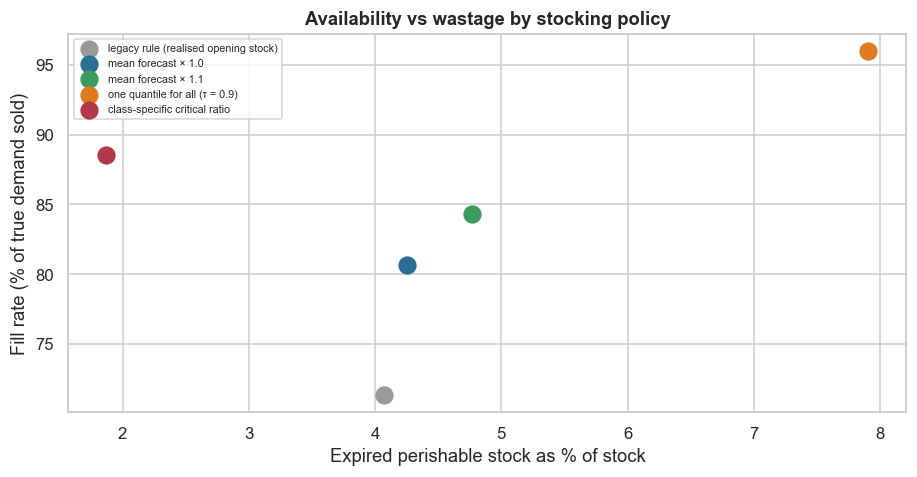

,fill rate (sold / true demand),wasted share of stock (perishables),leftover share (all),profit per store-SKU-day ₹,P(demand ≤ stock),Δ profit vs legacy,Δ CI low,Δ CI high
stocking policy,,,,,,,,
legacy rule (realised opening stock),0.7132,0.0407,0.2323,106.2375,0.6784,0.0000,0.0000,0.0000
mean forecast × 1.0,0.8063,0.0425,0.2524,118.2539,0.7277,12.0164,11.1343,13.0429
mean forecast × 1.1,0.8429,0.0477,0.2846,119.1813,0.7680,12.9438,11.7418,14.1186
one quantile for all (τ = 0.9),0.9600,0.0791,0.4691,94.9573,0.9398,-11.2801,-14.1149,-8.3463
class-specific critical ratio,0.8855,0.0187,0.4331,134.4734,0.8406,28.2359,26.5413,29.8590


In [12]:
qm = {}
for q in (0.4, 0.5, 0.7, 0.9):
    sub = np.random.default_rng(SEED).choice(len(Xtr_deb), 200_000, replace=False); qm[q] = np.clip(hgb("quantile", q).fit(Xtr_deb.iloc[sub][FEAT], y_deb[sub]).predict(Xte_deb[FEAT]), 0, None)
mean_p = PRED["4 GBM on de-biased demand"]; per = np.tile(meta.perishable.values, len(TE_DAYS)); pr = np.tile(meta.price_inr.values, len(TE_DAYS)); legacy_stock = np.concatenate([df.pivot(index="day", columns="series", values="opening_stock").values[d] for d in TE_DAYS])
cu = 0.25 * pr; co = np.where(per == 1, 0.5 * 0.70 * pr, 0.02 * pr)
POL = {"legacy rule (realised opening stock)": legacy_stock, "mean forecast × 1.0": np.ceil(mean_p), "mean forecast × 1.1": np.ceil(mean_p * 1.1), "one quantile for all (τ = 0.9)": np.ceil(qm[0.9]),
       "class-specific critical ratio": np.where(per == 1, np.ceil(qm[0.4]), np.ceil(qm[0.9] * 1.05))}
def evalpol(S, idx=None):
    D = y_true_te; sold = np.minimum(D, S); left = np.maximum(S - D, 0); profit = cu * sold - co * left; return sold, left, profit
rows = []; PROF = {}
for k, S in POL.items():
    sold, left, profit = evalpol(S); PROF[k] = profit.reshape(len(TE_DAYS), P_).mean(0)
    rows.append((k, sold.sum() / y_true_te.sum(), (left * (per == 1) * 0.5).sum() / S.sum(), left.sum() / S.sum(), profit.mean(), (y_true_te <= S).mean()))
pol = pd.DataFrame(rows, columns=["stocking policy", "fill rate (sold / true demand)", "wasted share of stock (perishables)", "leftover share (all)", "profit per store-SKU-day ₹", "P(demand ≤ stock)"]).set_index("stocking policy")
base_k = "legacy rule (realised opening stock)"
for k in POL:
    d_ = PROF[k] - PROF[base_k]; bs = [d_[i].mean() for i in (RNG.integers(0, P_, P_) for _ in range(500))]; pol.loc[k, "Δ profit vs legacy"] = d_.mean(); pol.loc[k, "Δ CI low"], pol.loc[k, "Δ CI high"] = np.percentile(bs, 2.5), np.percentile(bs, 97.5)
cov = [(q, (y_true_te <= np.ceil(qm[q])).mean(), stats.binomtest(int((y_true_te <= np.ceil(qm[q])).sum()), len(y_true_te), q, alternative="less").pvalue) for q in (0.4, 0.5, 0.7, 0.9)]
print("Quantile coverage (true demand ≤ stock; with integer stock coverage is ≥ τ, so the test is one-sided 'less'):", [(q, round(c, 3), f"p={p:.2g}") for q, c, p in cov])
CR_NP = cu[per == 0].mean() / (cu[per == 0].mean() + co[per == 0].mean()); CR_P = cu[per == 1].mean() / (cu[per == 1].mean() + co[per == 1].mean()); print(f"Critical ratios: non-perishable {CR_NP:.2f}, perishable {CR_P:.2f}")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for k, c_ in zip(POL, ["#999", "#2a6f97", "#3a9d5d", "#e07a1f", "#b23a48"]): ax.scatter(pol.loc[k, "wasted share of stock (perishables)"] * 100, pol.loc[k, "fill rate (sold / true demand)"] * 100, s=120, color=c_, label=k)
ax.set_xlabel("Expired perishable stock as % of stock"); ax.set_ylabel("Fill rate (% of true demand sold)"); ax.set_title("Availability vs wastage by stocking policy"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
pol.round(4)

**Takeaway:** **one service level for all SKUs is the wrong policy.** The legacy rule has a 71.3% fill rate and 4.07% of perishable stock expiring. A single τ = 0.9 quantile raises the fill rate to **96.0%** but expires **7.9%** of perishable stock and lowers profit by **₹11.3 per store-SKU-day** (CI −14.1 to −8.3). The **class-specific critical ratio** (0.93 for non-perishables, 0.42 for perishables) gives a fill rate of **88.5%**, cuts expiry to **1.87%** and earns **+₹28.2** (CI 26.5 to 29.9). Even the plain mean forecast × 1.1 earns +₹12.9, so about half of the gain comes from the forecast and the rest from the critical ratio. Quantile forecasts over-cover because stock is an integer (coverage 63% at τ = 0.4 up to 94% at τ = 0.9), which is conservative.

### 7.7 Where does the forecast fail? Segments and weekly stability

The aggregate hides weak spots. For the de-biased GBM we compute wMAPE and bias vs truth by segment (perishable, promo days, festival days, weekend, slow movers) and test **coverage of a nominal 90% quantile** by segment with exact binomial tests (BH across segments). We also report the wMAPE by test week to check **stability** of the model ranking over time.

#### Code

In [13]:
te = pd.DataFrame({"pred": mean_p, "true": y_true_te, "q90": np.ceil(qm[0.9]), "per": per, "promo": np.concatenate([promo[d] for d in TE_DAYS]), "fest": np.repeat(cal.festival.iloc[TE_DAYS].values, P_), "dow": np.repeat(cal.dow.iloc[TE_DAYS].values, P_),
                   "vol": tr_, "day": np.repeat(TE_DAYS, P_)})
segs = {"perishable": te.per == 1, "non-perishable": te.per == 0, "promo days": te.promo == 1, "no promo": te.promo == 0, "festival days": te.fest > 0, "weekend": te.dow >= 5, "weekday": te.dow < 5, "slow movers": te.vol == "slow movers", "fast movers": te.vol == "fast movers"}
rows = []
for nm, m in segs.items():
    s = te[m]
    if len(s) == 0: print(f"segment '{nm}' is empty - skipped"); continue
    bt = stats.binomtest(int((s.true <= s.q90).sum()), len(s), 0.9); rows.append((nm, len(s), wm(s.pred.values, s.true.values), (s.pred.sum() - s.true.sum()) / s.true.sum(), (s.true <= s.q90).mean(), bt.pvalue))
sg = pd.DataFrame(rows, columns=["segment", "rows", "wMAPE vs truth", "bias", "coverage of τ = 0.9 stock", "binomial p vs 0.9"]).set_index("segment"); sg["q_BH"] = mt(sg["binomial p vs 0.9"], method="fdr_bh")[1]
wk_rows = []
for w_, ds in enumerate((range(85, 92), range(92, 99), range(99, 105))):
    m = te.day.isin(list(ds)).values; wk_rows.append((f"week {w_ + 1}", *[wm(PRED[k][m], y_true_te[m]) for k in ("2 moving average (7-day sales)", "3 GBM on raw sales", "4 GBM on de-biased demand", "5 group-level GBM (GSKU) allocated to SKUs")]))
wkt = pd.DataFrame(wk_rows, columns=["test week", "moving average", "GBM raw", "GBM de-biased", "group GBM"]).set_index("test week")
display(wkt.round(4)); sg.round(4)

segment 'festival days' is empty - skipped


,moving average,GBM raw,GBM de-biased,group GBM
test week,,,,
week 1,0.4965,0.4872,0.4474,0.4545
week 2,0.4953,0.4860,0.4502,0.4564
week 3,0.4938,0.4853,0.4464,0.4512


,rows,wMAPE vs truth,bias,coverage of τ = 0.9 stock,binomial p vs 0.9,q_BH
segment,,,,,,
perishable,56800,0.4557,-0.0018,0.9423,0.0000,0.0000
non-perishable,103200,0.4444,-0.0044,0.9385,0.0000,0.0000
promo days,11117,0.4319,-0.0227,0.9231,0.0000,0.0000
no promo,148883,0.4497,-0.0016,0.9411,0.0000,0.0000
weekend,48000,0.4332,-0.0191,0.9306,0.0000,0.0000
weekday,112000,0.4561,0.0048,0.9438,0.0000,0.0000
slow movers,53660,0.8206,0.0917,0.9693,0.0000,0.0000
fast movers,53300,0.3933,-0.0165,0.9123,0.0000,0.0000


**Observation:** the de-biased GBM is the best model in all three test weeks (0.447, 0.450 and 0.446, against 0.485 to 0.487 for raw sales and 0.494 to 0.497 for the moving average), so the result is stable. Coverage of the τ = 0.9 stock is **above 90% in every segment** (92 to 97%), meaning the policy errs towards over-stocking. It is highest for **slow movers (96.9%)**, where it wastes stock, and lowest for fast movers (91.2%). Promo and weekend days have slightly higher forecast error bias (−2.3% and −1.9%). The **festival days segment is empty** in the test window (the festivals fall earlier), so festival behaviour is untested. The p-values from the two-sided binomial test reflect over-coverage, not under-coverage.

## 8. ML Section — what we built and what Instamart adds

- **Our models:** gradient boosting on lagged, calendar and availability features (no tuning, per the brief), and a group-level variant for the GSKU idea; quantile GBMs for the stocking decision.
- **What Instamart adds (documented, second-hand):** a zero-shot **time-series foundation model (TimesFM)** with covariates via ridge regression, and a deeper store × category × SKU hierarchy. The decision-relevant lessons here (de-bias first, group substitutes, evaluate on availability and wastage) apply to any model, including a foundation model.
- **Practical note:** retrain nightly on the de-biased target, and recompute availability and the intraday profile continuously.

## 9. Business Translation — ₹ impact

Assumptions (D-7-07): the 200-SKU core assortment simulated here; **1,000 dark stores**; the gains are per store-day for these 200 SKUs, so scaling to a full 10,000-SKU assortment is linear but optimistic (the long tail is slower and noisier).

#### Code

In [14]:
STORES = 1000; best = pol["profit per store-SKU-day ₹"].idxmax(); d = pol.loc["class-specific critical ratio", "Δ profit vs legacy"]; lo, hi = pol.loc["class-specific critical ratio", "Δ CI low"], pol.loc["class-specific critical ratio", "Δ CI high"]
scen = {"worst (CI low, ×0.5 for long-tail drag)": lo * 0.5, "base (point estimate)": d, "best (CI high)": hi}
money = pd.DataFrame([(k, v, v * 200 * STORES * 365 / 1e7) for k, v in scen.items()], columns=["scenario", "Δ ₹ per store-SKU-day", "₹ crore / year (1,000 stores × 200 core SKUs)"]).set_index("scenario")
print(f"Highest-profit policy on the test days: {best}")
print(f"Class-specific vs legacy: fill rate {pol.loc['class-specific critical ratio', 'fill rate (sold / true demand)']:.1%} vs {pol.loc[base_k, 'fill rate (sold / true demand)']:.1%}; expired perishable share {pol.loc['class-specific critical ratio', 'wasted share of stock (perishables)']:.2%} vs {pol.loc[base_k, 'wasted share of stock (perishables)']:.2%}")
money.round(3)

Highest-profit policy on the test days: class-specific critical ratio
Class-specific vs legacy: fill rate 88.5% vs 71.3%; expired perishable share 1.87% vs 4.07%


,Δ ₹ per store-SKU-day,"₹ crore / year (1,000 stores × 200 core SKUs)"
scenario,,
"worst (CI low, ×0.5 for long-tail drag)",13.2710,96.8760
base (point estimate),28.2360,206.1220
best (CI high),29.8590,217.9710


**Takeaway (business reading):** class-specific critical ratios add **₹28.2 per store-SKU-day** (CI 26.5 to 29.9), about **₹206 crore a year** at 1,000 stores and 200 core SKUs (pessimistic ₹97 crore after halving for the slower long tail, optimistic ₹218 crore). The gain comes from three places: higher availability on non-perishables, less expiry of perishables, and a de-biased forecast. It is a linear scale-up of a 200-SKU assortment and a simulated cost structure, so treat it as an order of magnitude.

## 10. Recommendation and Decision

**Recommendation**

1. **Train on de-biased demand**, scaled by observed availability, and keep an estimated intraday profile to refine it.
2. **Evaluate against estimated true demand and availability**, not recorded sales. Report both, because the two rankings disagree (Spearman −0.50).
3. **Stock by class.** Use a high critical ratio for non-perishables (≈ 0.93) and a low one for perishables (≈ 0.42), not one service level.
4. **Keep SKU-level forecasts**; use grouping for substitution and availability estimation, not for accuracy.
5. **Validate with a store-level holdout** on fill rate, expiry and profit before rollout.

**Decision rule:** roll out if fill rate rises by at least 10 points and expiry does not rise.

**Not yet known:** festival behaviour (untested), the real intraday profile, and long-tail SKU performance.

## 11. Risks, Limitations and Next Steps

- **Simulated censoring:** the intraday profile, spill-over rate and the legacy rule were assumed. Real stores also have **late deliveries, phantom inventory and picking errors** that distort availability signals. Audit the availability logs.
- **De-biasing needs the intraday profile:** if the profile is wrong (a festival changes the shape of the day), profile scaling errs. Re-estimate by day type.
- **Evaluating on truth is possible only in simulation.** In practice use the **estimated** availability and wastage (Instamart's approach), plus **randomised store holdouts** (switchback or store-level) to measure the real effect.
- **Newsvendor assumes independent items:** pick-capacity and shelf-space limits couple them. Add constraints (a knapsack) for tight stores.
- **Next steps:** pilot class-specific stocking in 20 stores for 4 weeks (store-level randomisation, pre-registered availability and wastage metrics); add cold-start handling for new SKUs (Case 11); consider a foundation-model benchmark.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Censored sales | sales = min(demand, stock) (plus spill-over) |
| Availability | share of open hours the SKU was orderable |
| Profile de-biasing | demand ≈ sales / F(a), F = cumulative intraday demand share at availability a |
| wMAPE | Σ|forecast − actual| / Σ actual |
| Newsvendor | stock* = F⁻¹(Cu / (Cu + Co)) |
| Fill rate | Σ min(D, S) / Σ D |
| Bootstrap over series | resample the 8,000 store-SKU series with replacement |

| Term | Meaning |
|---|---|
| Dark store | A small warehouse that fulfils quick-commerce orders |
| SKU / GSKU | Stock-keeping unit / group of substitutable SKUs |
| Censored demand | True demand that is hidden because the item sold out |
| Availability | The share of open hours an item can be ordered |
| Wastage | Perishable stock that expires unsold |
| Critical ratio | Underage cost ÷ (underage + overage cost): the target service level |
| Quantile forecast | A forecast of a chosen percentile of demand |